# Lecture 22 part 2: Plotting in Python

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## State-based method, for only one plot

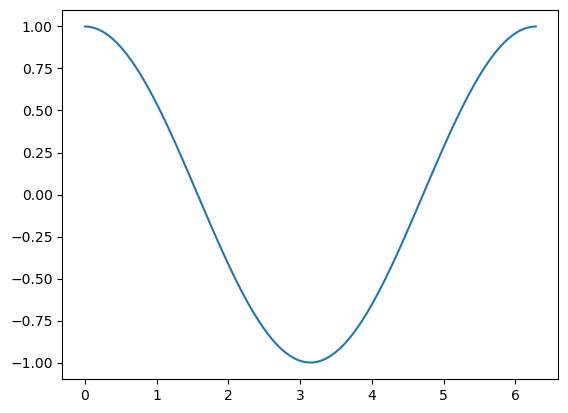

In [31]:
x = np.linspace(0, 2*np.pi, 100)
y = np.cos(x)
plt.plot(x, y);  # use plt.plot for one plot

## Object Oriented Method, for one or more plots. This is much better to use in general!

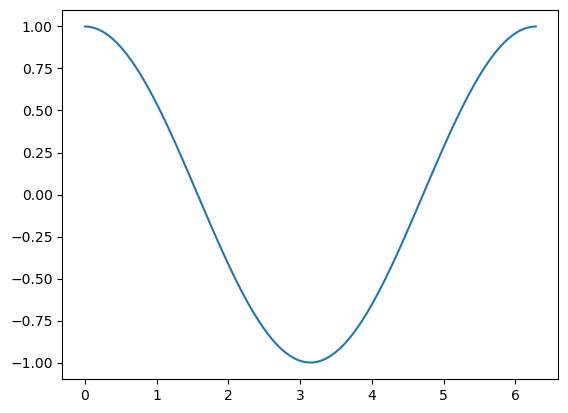

In [33]:
fig, ax = plt.subplots() #ax is the image plotted, while fig is the window for the image.
x = np.linspace(0, 2*np.pi, 100)
ax.plot(x, np.cos(x)); 

## Multiple Plots
**Goal:** plot $y = \cos(kx)$ for $k = 1, 2, 3, 5, 7, 10$ between $x=0$ and $x=2\pi$.
- Plot using a single ax
- Plot using multiple axes

In [35]:
k_list = [1, 2, 3, 5, 7, 10]
x = np.linspace(0, 2*np.pi, 500) #domain

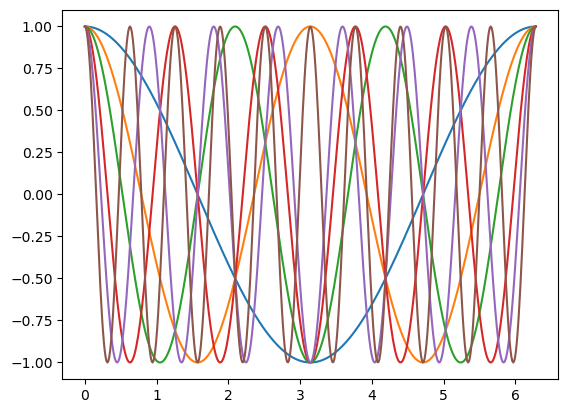

In [37]:
fig, ax = plt.subplots()
for k in k_list:
    f = lambda x: np.cos(k * x)  #lambda function, similar to function handles in Matlab
    y = f(x)
    ax.plot(x,y); #As long as I use the same ax variable for each plot, new pictures go into the same plot.

The plot above is very messy! What if we want multiple windows for our plots?

In [39]:
help(plt.subplots)

Help on function subplots in module matplotlib.pyplot:

subplots(nrows: 'int' = 1, ncols: 'int' = 1, *, sharex: "bool | Literal['none', 'all', 'row', 'col']" = False, sharey: "bool | Literal['none', 'all', 'row', 'col']" = False, squeeze: 'bool' = True, width_ratios: 'Sequence[float] | None' = None, height_ratios: 'Sequence[float] | None' = None, subplot_kw: 'dict[str, Any] | None' = None, gridspec_kw: 'dict[str, Any] | None' = None, **fig_kw) -> 'tuple[Figure, Any]'
    Create a figure and a set of subplots.

    This utility wrapper makes it convenient to create common layouts of
    subplots, including the enclosing figure object, in a single call.

    Parameters
    ----------
    nrows, ncols : int, default: 1
        Number of rows/columns of the subplot grid.

    sharex, sharey : bool or {'none', 'all', 'row', 'col'}, default: False
        Controls sharing of properties among x (*sharex*) or y (*sharey*)
        axes:

        - True or 'all': x- or y-axis will be shared amon

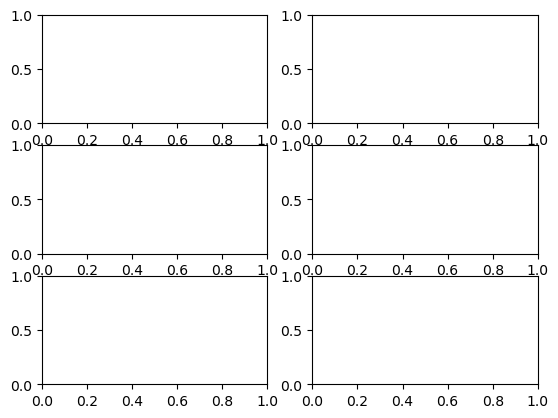

In [41]:
fig, axs = plt.subplots(3,2)

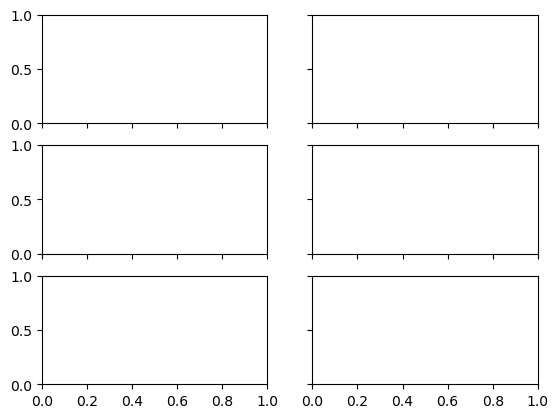

In [43]:
fig, axs = plt.subplots(3,2, sharex = True, sharey = True)

In [45]:
type(axs)

numpy.ndarray

In [47]:
axs.shape

(3, 2)

In [49]:
axs_flat = axs.reshape(-1)  #makes it easier to assign different plots to different figure windows

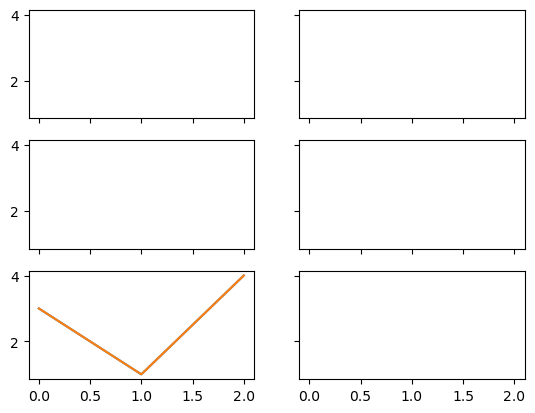

In [53]:
axs_flat[4].plot([3, 1, 4]); #index 4 is the 5th figure window.
fig

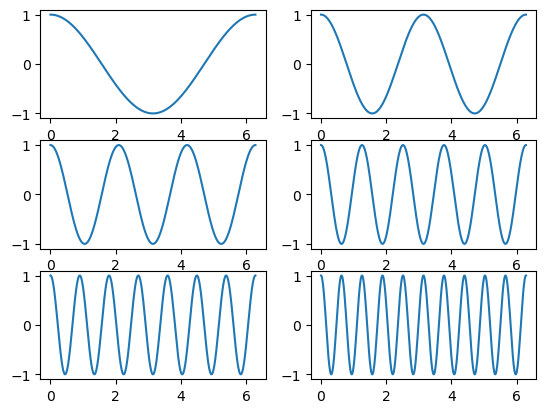

In [55]:
fig, axs = plt.subplots(3, 2)
axs_flat = axs.reshape(-1)

for i in range(len(k_list)):
    k = k_list[i]
    ax = axs_flat[i]
    f = lambda x: np.cos(k * x)
    y = f(x)
    ax.plot(x,y);

### **Goal:** clean up this code a bit

Create a `zip` object, then for loop on it.

In [72]:
#Recall: example of a zip object
a_list = [7, 8, 9, 10]
b_list = [3, 4, 5]
for a, b in zip(a_list, b_list):
    print(a, b)  #Note that we only pair elements up to the length of the smallest list.

7 3
8 4
9 5


`zip` pairs objects from two lists together. It's similar to creating tuples from each list.

In [74]:
zip(a_list,b_list)

In [76]:
list(zip(a_list, b_list))

[(7, 3), (8, 4), (9, 5)]

You can zip together 3 or more lists, but we only need two for creating subplots.

In [66]:
list(zip(a_list, a_list, b_list, b_list, b_list, b_list, b_list, b_list))

[(7, 7, 3, 3, 3, 3, 3, 3), (8, 8, 4, 4, 4, 4, 4, 4), (9, 9, 5, 5, 5, 5, 5, 5)]

The code below, with a for loop on a zip object, is shorter and simpler to use than the for loop on an enumerate object.

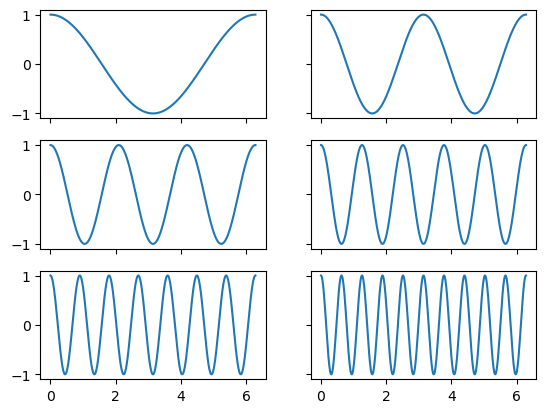

In [68]:
fig, axs = plt.subplots(3, 2, sharex = True, sharey = True)
axs_flat = axs.reshape(-1)

for k, ax in zip(k_list, axs_flat):
    f = lambda x: np.cos(k * x)
    y = f(x)
    ax.plot(x,y);

## Further Labeling and Styling in Matplotlib

Please also take a look at Yasmeen Baki's video in the Matplotlib series "Adjusting the Appearance" to learn more about how to make these graphs look nice: https://www.youtube.com/watch?v=3d8ahlcQhRY

The video linked is well worth your time. The picture below is the result of each adjustment from the video:

In [54]:
from matplotlib.colors import CSS4_COLORS

In [56]:
plt.style.available

['Solarize_Light2',
 '_classic_test_patch',
 '_mpl-gallery',
 '_mpl-gallery-nogrid',
 'bmh',
 'classic',
 'dark_background',
 'fast',
 'fivethirtyeight',
 'ggplot',
 'grayscale',
 'seaborn-v0_8',
 'seaborn-v0_8-bright',
 'seaborn-v0_8-colorblind',
 'seaborn-v0_8-dark',
 'seaborn-v0_8-dark-palette',
 'seaborn-v0_8-darkgrid',
 'seaborn-v0_8-deep',
 'seaborn-v0_8-muted',
 'seaborn-v0_8-notebook',
 'seaborn-v0_8-paper',
 'seaborn-v0_8-pastel',
 'seaborn-v0_8-poster',
 'seaborn-v0_8-talk',
 'seaborn-v0_8-ticks',
 'seaborn-v0_8-white',
 'seaborn-v0_8-whitegrid',
 'tableau-colorblind10']

In [58]:
plt.style.use("seaborn-v0_8-darkgrid")

In [70]:
rng = np.random.default_rng()

In [72]:
random_colors = rng.choice(list(CSS4_COLORS.keys()), size=len(k_list))

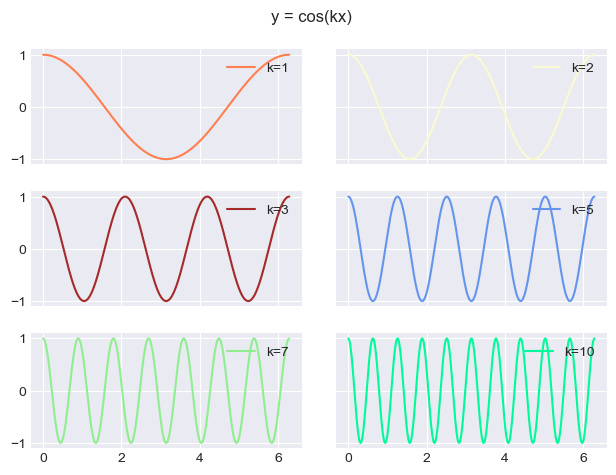

In [74]:
fig, axs = plt.subplots(3, 2, sharex = True, sharey = True)
axs_flat = axs.reshape(-1)
fig.suptitle("y = cos(kx)")
fig.tight_layout() #keeps each subplot from being squished together


for k, ax, color in zip(k_list, axs_flat, random_colors):
    f = lambda x: np.cos(k * x)
    y = f(x)
    ax.plot(x,y, label=f"k={k}", c=color);  #added label for legend
    ax.legend(loc="upper right")   #without this line, the legend will not actually show